# EDA: Interim Data

**Goal:** answer the questions `clean.py` and the `combine_datasets()` function in `combine.py` still need answered.

This notebook only *looks* at the data. Anything decided here becomes code in `clean.py` and `combine.py`.

In [4]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from forecast import configure

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

reservoir_volumes = pd.read_csv(configure.SAWATER_COMBINED, parse_dates=["month", "date"])
rain = pd.read_csv(configure.RAINFALL_COMBINED, parse_dates=["month"], dtype={"station": str})

STUDY_START, STUDY_END = reservoir_volumes["month"].min(), reservoir_volumes["month"].max()
print(reservoir_volumes.shape, rain.shape, "| study period:", STUDY_START.date(), "->", STUDY_END.date())

(1000, 10) (9821, 4) | study period: 2018-05-31 -> 2026-09-30


## SA Water reservoir dataset

### 1.1 Capacity
Check any capacities that are blank (EDA_raw records 4.)

Also check how many distinct values each reservoir has.

In [5]:
# Rows with blank capacity
reservoir_volumes.loc[reservoir_volumes["capacity_ml"].isna(), ["reservoir", "month", "volume_ml", "source_file"]]

,reservoir,month,volume_ml,source_file
516,Middle River Reservoir,2026-01-31,448.15,reservoir-volumes-for-january-2026.csv
517,Middle River Reservoir,2026-02-28,390.02,reservoir-volumes-for-february-2026.csv
518,Middle River Reservoir,2026-03-31,338.88,reservoir-volumes-for-march-2026.csv
519,Middle River Reservoir,2026-04-30,309.35,reservoir-volumes-for-april-2026.csv


In [6]:
cap = reservoir_volumes.groupby("reservoir")["capacity_ml"].agg(
    distinct="nunique", min="min", max="max", blanks=lambda s: s.isna().sum()
)
cap["range_pct"] = (cap["max"] - cap["min"]) / cap["max"] * 100
cap.sort_values("range_pct", ascending=False)

,distinct,min,max,blanks,range_pct
reservoir,,,,,
South Para Reservoir,2,44435.00,44833.97,0,0.889883
Warren Reservoir,2,4711.00,4731.44,0,0.432004
Happy Valley Reservoir,2,12598.36,12650.00,0,0.408221
Mt Bold Reservoir,2,46400.02,46545.00,0,0.311484
Hope Valley Reservoir,2,2934.70,2935.00,0,0.010221
Kangaroo Creek Reservoir,2,18684.67,18685.00,0,0.001766
Millbrook Reservoir,2,15714.73,15715.00,0,0.001718
Myponga Reservoir,2,27565.00,27565.21,0,0.000762
Little Para Reservoir,2,20890.88,20891.00,0,0.000574


#### Follow-Up: When does reservoir capacity change?

In [7]:
changes = (
    reservoir_volumes.sort_values("month")
    .assign(prev=lambda d: d.groupby("reservoir")["capacity_ml"].shift())
    .query("capacity_ml != prev and prev.notna()", engine="python")
    [["reservoir", "month", "prev", "capacity_ml"]]
)
changes

,reservoir,month,prev,capacity_ml
295,Kangaroo Creek Reservoir,2019-03-31,18685.0,18684.67
630,Mt Bold Reservoir,2019-03-31,46545.0,46400.02
725,Myponga Reservoir,2019-03-31,27565.0,27565.21
10,Barossa Reservoir,2019-03-31,4375.0,4375.02
105,Happy Valley Reservoir,2019-03-31,12650.0,12598.36
200,Hope Valley Reservoir,2019-03-31,2935.0,2934.70
915,Warren Reservoir,2019-03-31,4711.0,4731.44
390,Little Para Reservoir,2019-03-31,20891.0,20890.88
820,South Para Reservoir,2019-03-31,44435.0,44833.97
535,Millbrook Reservoir,2019-03-31,15715.0,15714.73


### 1.2 Volume over Capacity
Look for zeros, spikes, and other implausible values.

In [8]:
rv = reservoir_volumes.sort_values(["reservoir", "month"])

# Capacity in force at each reading; the 4 blanks borrow the nearest month's value (this check only)
cap_at_reading = rv.groupby("reservoir")["capacity_ml"].transform(lambda s: s.ffill().bfill())

rv["pct_full"] = rv["volume_ml"] / cap_at_reading * 100           # vs capacity at the time

over = rv[(rv["pct_full"] > 100)]
print(len(over), "readings above 100%")
over.groupby("reservoir")[["pct_full"]].agg(["count", "max"]).round(1)

41 readings above 100%


pct_full       
                            count    max
reservoir                               
Kangaroo Creek Reservoir        3  101.0
Middle River Reservoir         13  117.1
Warren Reservoir               25  106.3

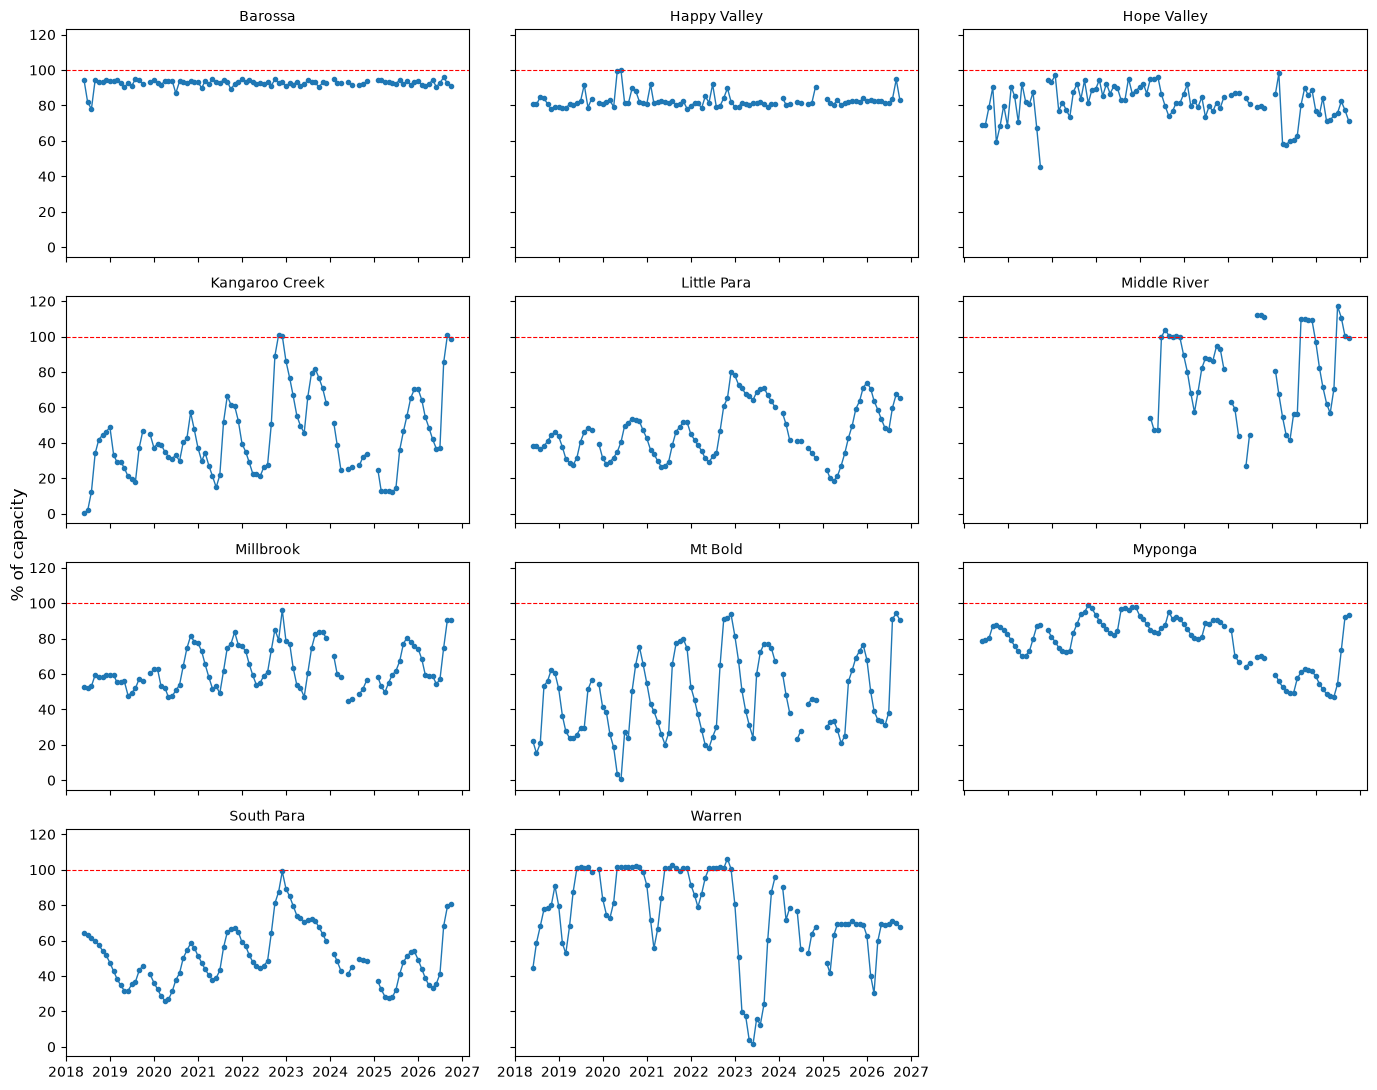

In [11]:
reservoirs = sorted(reservoir_volumes["reservoir"].unique())
fig, axes = plt.subplots(4, 3, figsize=(14, 11), sharex=True, sharey=True)
for ax, name in zip(axes.flat, reservoirs):
    s = rv[rv["reservoir"] == name].set_index("month")["pct_full"]
    s = s.reindex(pd.date_range(STUDY_START, STUDY_END, freq="ME"))   # gaps show as breaks
    ax.plot(s.index, s.values, marker=".", lw=1)
    ax.axhline(100, color="red", lw=0.8, ls="--")
    ax.set_title(name.replace(" Reservoir", ""), fontsize=10)
for ax in axes.flat[len(reservoirs):]:
    ax.axis("off")
fig.supylabel("% of capacity")
plt.tight_layout()
plt.show()

### 1.3 Missing Months
One strong potential fix to the problem of 6 months of missing data is to look at the file a year after the missing month. This is NOT to assume that the volume last year can be filled in with this year's value.

Instead, each file reports *volume this day last year*. So the file for month *m + 12* contains the volume for month *m*, even if no file was recorded in month *m*.

But for this to work, we need to confirm that the *volume this day last year* values are accurate for those months that are known.

In [12]:
# volume_last_year_ml in month m  ->  the volume for month m - 12
lagged = reservoir_volumes[["reservoir", "month", "volume_last_year_ml"]].copy()
lagged["month"] = lagged["month"] - pd.DateOffset(months=12) + pd.offsets.MonthEnd(0)
lagged = lagged.rename(columns={"volume_last_year_ml": "recovered_ml"})

check = reservoir_volumes[["reservoir", "month", "volume_ml"]].merge(lagged, on=["reservoir", "month"])
check["error_ml"] = check["recovered_ml"] - check["volume_ml"]
check["error_pct_of_volume"] = check["error_ml"].abs() / check["volume_ml"] * 100

print(len(check), "months where both values exist")
print(check["error_pct_of_volume"].describe().round(2))

814 months where both values exist
count    814.00
mean       0.76
std        3.26
min        0.00
25%        0.00
50%        0.00
75%        0.52
max       77.75
Name: error_pct_of_volume, dtype: float64


In [13]:
# 1. Top 10 largest volume errors (in ML, magnitude regardless of sign)
top_ml_outliers = check.reindex(
    check["error_ml"].abs().sort_values(ascending=False).index
).head(10)

print("Top 10 Outliers by Absolute Volume Error (ML):")
print(
    top_ml_outliers[
        [
            "reservoir",
            "month",
            "volume_ml",
            "recovered_ml",
            "error_ml",
            "error_pct_of_volume",
        ]
    ]
)

Top 10 Outliers by Absolute Volume Error (ML):
                    reservoir      month  volume_ml  recovered_ml  error_ml  error_pct_of_volume
521         Mt Bold Reservoir 2020-02-29   12092.02      13761.16   1669.14            13.803649
510         Mt Bold Reservoir 2019-02-28   12908.79      11608.75  -1300.04            10.070967
531         Mt Bold Reservoir 2020-12-31   25433.02      24485.10   -947.92             3.727123
733      South Para Reservoir 2025-07-31   18453.54      19284.90    831.36             4.505152
242  Kangaroo Creek Reservoir 2019-02-28    5434.78       4676.28   -758.50            13.956407
577         Mt Bold Reservoir 2025-07-31   25936.64      25266.53   -670.11             2.583642
309  Kangaroo Creek Reservoir 2025-07-31    6714.58       7306.77    592.19             8.819465
387     Little Para Reservoir 2025-07-31    8959.31       9451.97    492.66             5.498861
507         Mt Bold Reservoir 2018-11-30   28146.94      27660.59   -486.35     

In [14]:
# Which missing months could be filled this way?
all_months = pd.date_range(STUDY_START, STUDY_END, freq="ME")
missing_months = all_months.difference(pd.DatetimeIndex(reservoir_volumes["month"].unique()))

fillable = lagged[lagged["month"].isin(missing_months)]

fillable_set = set(fillable["month"])
print("Missing months:")
for m in missing_months:
    status = " -> fillable" if m in fillable_set else ""
    print(f"  • {m.strftime('%B %Y')}{status}")

Missing months:
  • October 2019 -> fillable
  • December 2023
  • April 2024 -> fillable
  • July 2024 -> fillable
  • November 2024 -> fillable
  • December 2024 -> fillable


### Findings: SA Water
Used to inform `clean_reservoir_volumes()`

- Middle River Reservoir should be discarded because 
    1) it only started recording data in March 2022 (leaving less data for SARIMA to work with than all the others) 
    2) all four of the missing capacity measures come from this reservoir, meaning if it's discarded all capacity measures will be fully accounted for
    3) volume exceeds 100% capacity in 13 instances, with a maximum excess of 117.1% (which could lead the forecasting model to incorrectly predict volumes > capacities or - if it doesn't - make it seem to perform poorly on this one reservoir)
- Warren Reservoir's volume also exceeds 100% capacity (in 25 instances.) However, this reservoir should not be discarded because the maximum excess is only 106.3% and these aren't spikes but consistent patterns.
- It seems all 10 reservoirs excluding Middle River had a re-surveying of capacity in March 2019. However, the change in capacity estimation didn't exceed 1% for any of the reservoirs. It is assumed safe, therefore, to use the updated value as the single capacity measure. 
- The "volume this day last year" field seems highly accurate, with a mean error less than 1% of volume, and even the top 10 errors ranging from 1-14%. Therefore, the solution of using this measure to fill the missing months is acceptable and will account for all but December 2023, which will likely need mean interpolation between November 2023 and January 2024.

## BoM (Bureau of Meteorology) monthly rainfall dataset

### 2.1 Reservoir-Station Mapping
Station coordinates come from each station's `_Note.txt`; reservoir coordinates from the SA Water data.

In [15]:
def station_coords(station):
    """Read latitude/longitude from a BoM _Note.txt file."""
    note = next(configure.DATA_RAW_BOM.glob(f"*_{station}_Note.txt"), None)
    if note is None:
        return pd.Series({"st_lat": np.nan, "st_lon": np.nan})
    text = note.read_text(encoding="utf-8", errors="ignore")
    lat = float(re.search(r"Latitude.*?:\s*(-?[\d.]+)", text).group(1))
    lon = float(re.search(r"Longitude.*?:\s*(-?[\d.]+)", text).group(1))
    return pd.Series({"st_lat": lat, "st_lon": lon})


def km_between(lat1, lon1, lat2, lon2):
    """Great-circle distance in km."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


# One coordinate per reservoir (median skips the blank rows found in EDA_raw)
pairs = reservoir_volumes.groupby("reservoir")[["latitude", "longitude"]].median()
pairs["station"] = pairs.index.map(configure.RAIN_STATIONS)
pairs = pairs.join(pairs["station"].apply(station_coords))
pairs["km"] = km_between(pairs["latitude"], pairs["longitude"], pairs["st_lat"], pairs["st_lon"]).round(1)
pairs

,latitude,longitude,station,st_lat,st_lon,km
reservoir,,,,,,
Barossa Reservoir,-34.65,138.85,023752,-34.65,138.88,2.7
Happy Valley Reservoir,-35.07,138.57,023721,-35.06,138.57,1.1
Hope Valley Reservoir,-34.85,138.68,023096,-34.86,138.68,1.1
Kangaroo Creek Reservoir,-34.86,138.78,023892,-34.89,138.76,3.8
Little Para Reservoir,-34.74,138.72,023915,-34.75,138.72,1.1
Middle River Reservoir,-35.71,137.09,022835,-35.73,137.12,3.5
Millbrook Reservoir,-34.82,138.81,023731,-34.83,138.82,1.4
Mt Bold Reservoir,-35.11,138.70,023734,-35.12,138.68,2.1
Myponga Reservoir,-35.39,138.43,023783,-35.40,138.43,1.1


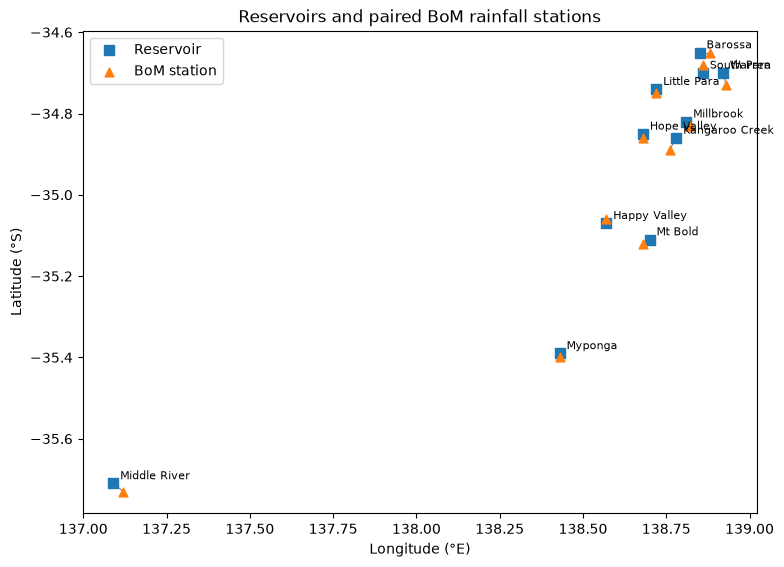

In [16]:
fig, ax = plt.subplots(figsize=(8, 8))
for name, r in pairs.iterrows():
    ax.plot([r["longitude"], r["st_lon"]], [r["latitude"], r["st_lat"]], color="0.6", lw=1, zorder=1)
ax.scatter(pairs["longitude"], pairs["latitude"], s=60, marker="s", label="Reservoir", zorder=2)
ax.scatter(pairs["st_lon"], pairs["st_lat"], s=40, marker="^", label="BoM station", zorder=3)
for name, r in pairs.iterrows():
    ax.annotate(name.replace(" Reservoir", ""), (r["longitude"], r["latitude"]),
                xytext=(5, 3), textcoords="offset points", fontsize=8)

# Equal distances in both directions at this latitude
ax.set_aspect(1 / np.cos(np.radians(pairs["latitude"].mean())))
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°S)")
ax.set_title("Reservoirs and paired BoM rainfall stations")
ax.legend()
plt.tight_layout()
plt.show()

Another, stronger reason in favor of disregarding Middle River Reservoir: It's in Kangaroo Island, presumably not fed by the same metropolitan network

### 2.2 Missing Rainfall Measuremtns
For each station with gaps in the study period, the other stations are ranked by how closely their monthly rainfall tracks it. Whichever station has the highest correlation with the station that has a gap will be used as a donor to fill the missing value.

In [17]:
wide = (rain[rain["month"] >= "2000-01-01"]
        .pivot_table(index="month", columns="station", values="rain_mm"))
corr = wide.corr(min_periods=60)       # require at least 5 years of overlap

study = rain[rain["month"].between(STUDY_START, STUDY_END)]
study_wide = study.pivot_table(index="month", columns="station", values="rain_mm").reindex(all_months)
gap_counts = study_wide.isna().sum()
gap_stations = gap_counts[gap_counts > 0].index
print("stations with gaps in the study period:", dict(gap_counts[gap_counts > 0]))

station_xy = pairs.set_index("station")[["st_lat", "st_lon"]]
rows = []
for stn in gap_stations:
    for donor, r in corr[stn].drop(stn).nlargest(1).items():
        # can the donor actually fill this station's gap months?
        gaps = study_wide.index[study_wide[stn].isna()]
        covers = study_wide.loc[gaps, donor].notna().sum()
        rows.append({
            "station": stn, "donor": donor, "corr": round(r, 3),
            "km": round(km_between(*station_xy.loc[stn], *station_xy.loc[donor]), 1),
            "gaps": len(gaps), "donor_covers": covers,
        })
pd.DataFrame(rows)

stations with gaps in the study period: {'023096': np.int64(2), '023731': np.int64(2), '023783': np.int64(7), '023820': np.int64(2), '023915': np.int64(10)}


,station,donor,corr,km,gaps,donor_covers
0,023096,023915,0.964,12.8,2,2
1,023731,023096,0.944,13.2,2,2
2,023783,023721,0.933,39.9,7,7
3,023820,023752,0.978,3.8,2,2
4,023915,023096,0.964,12.8,10,10


### 2.3 Merge preview

In [21]:
# Map each reservoir to its assigned BoM station
rv_with_station = reservoir_volumes.assign(
    station=reservoir_volumes["reservoir"].map(configure.RAIN_STATIONS)
)

# Left join SA Water with BoM rainfall on ['station', 'month']
merged_preview = rv_with_station.merge(
    rain, on=["station", "month"], how="left"
)

# Confirm that row count is preserved
row_count_preserved = len(merged_preview) == len(reservoir_volumes)
print(
    f"Row count preserved: {row_count_preserved} "
    f"({len(merged_preview)} == {len(reservoir_volumes)})"
)

#print preview of the merged data
merged_preview.head(10)

Row count preserved: True (1000 == 1000)


,month,reservoir,date,capacity_ml,volume_ml,volume_last_year_ml,avg_volume_month_ml,latitude,longitude,source_file,station,rain_mm,quality
0,2018-05-31,Barossa Reservoir,2018-05-31,4375.0,4120.57,4030.01,4076.05,-34.65,138.85,sawpfsc02homeve002087desktopopen-datareservoir...,023752,59.0,Y
1,2018-06-30,Barossa Reservoir,2018-07-02,4375.0,3575.34,4109.47,3585.53,-34.65,138.85,sawpfsc02homeve002087desktopopen-datareservoir...,023752,52.8,Y
2,2018-07-31,Barossa Reservoir,2018-07-30,4375.0,3414.44,3996.31,3291.55,-34.65,138.85,sawpfsc02homesc002322reservoir-volumes-for-jul...,023752,45.6,Y
3,2018-08-31,Barossa Reservoir,2018-08-31,4375.0,4131.31,4063.93,3970.49,NaN,NaN,sawpfsc02homeve002087desktopreservoirvolumesfo...,023752,100.0,Y
4,2018-09-30,Barossa Reservoir,2018-09-29,4375.0,4088.40,4052.60,4078.47,-34.65,138.85,sawpfsc02homeve002087desktopreservoirvolumesfo...,023752,35.4,Y
5,2018-10-31,Barossa Reservoir,2018-10-31,4375.0,4066.99,4132.38,4061.88,-34.65,138.85,sawpfsc02homeve002087desktopreservoirvolumesfo...,023752,34.2,Y
6,2018-11-30,Barossa Reservoir,2018-11-30,4375.0,4131.31,4041.30,4071.69,-34.65,138.85,sawpfsc02homeve002087desktopinternet-metro-res...,023752,66.8,Y
7,2018-12-31,Barossa Reservoir,2019-01-02,4375.0,4099.12,4132.38,4093.76,-34.65,138.85,sawpfsc02homeve002087desktopreservoirvolumesfo...,023752,15.4,Y
8,2019-01-31,Barossa Reservoir,2019-01-31,4375.0,4099.12,4030.01,4078.83,-34.65,138.85,sawpfsc02homesc002322desktopreservoirvolumesfo...,023752,1.2,Y
9,2019-02-28,Barossa Reservoir,2019-02-28,4375.0,4131.31,4088.40,4086.93,-34.65,138.85,sawpfsc02homesc002322desktopreservoirvolumesfo...,023752,6.6,Y


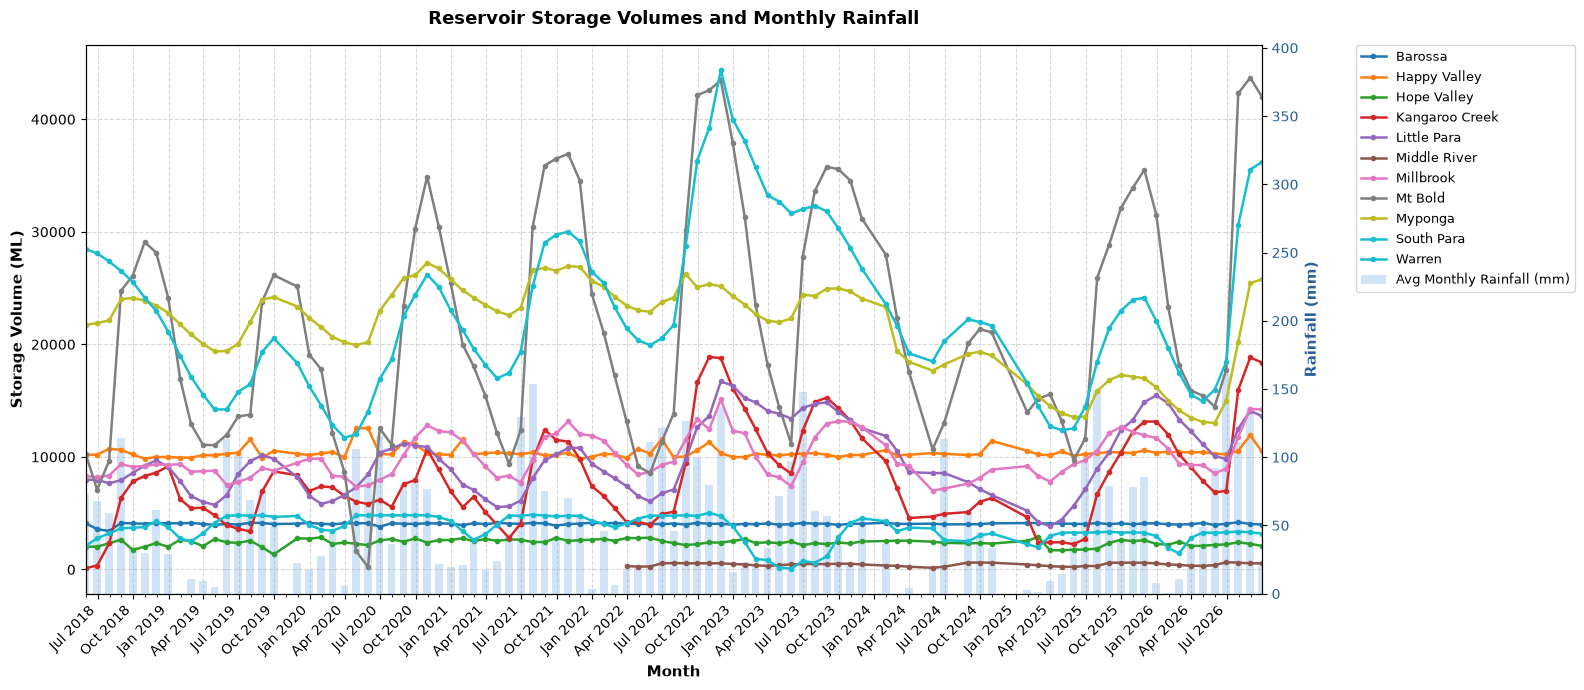

In [ ]:
import matplotlib.dates as mdates

fig, ax1 = plt.subplots(figsize=(16, 7))

# Secondary Y-axis: Rainfall
ax2 = ax1.twinx()
# Mean rainfall across stations per month from merged_preview
monthly_rain = (
    merged_preview.groupby("month")["rain_mm"].mean().sort_index()
)

ax2.bar(
    monthly_rain.index,
    monthly_rain.values,
    width=20,
    color="#4a90e2",
    alpha=0.25,
    label="Avg Monthly Rainfall (mm)",
    zorder=1,
)
ax2.set_ylabel("Rainfall (mm)", color="#2a6099", fontsize=11, weight="bold")
ax2.tick_params(axis="y", labelcolor="#2a6099")
ax2.set_ylim(0, monthly_rain.max() * 2.5)
ax2.grid(False)

# Primary Y-axis: Reservoir Volumes
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)

reservoirs = merged_preview["reservoir"].unique()
colors = plt.cm.tab10(np.linspace(0, 1, len(reservoirs)))

for res_name, color in zip(reservoirs, colors):
    res_data = merged_preview[
        merged_preview["reservoir"] == res_name
    ].sort_values("month")
    ax1.plot(
        res_data["month"],
        res_data["volume_ml"],
        marker="o",
        markersize=3,
        linewidth=1.8,
        label=res_name.replace(" Reservoir", ""),
        color=color,
    )

ax1.set_ylabel("Storage Volume (ML)", fontsize=11, weight="bold")
ax1.set_xlabel("Month", fontsize=11, weight="bold")

#  X-axis formatting
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_minor_locator(mdates.MonthLocator(interval=1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha="right")

ax1.set_xlim(merged_preview["month"].min(), merged_preview["month"].max())
ax1.grid(True, linestyle="--", alpha=0.5)

# Combined Legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="upper left",
    bbox_to_anchor=(1.08, 1),
    borderaxespad=0.0,
    frameon=True,
    fontsize=9,
)

plt.title(
    "Reservoir Storage Volumes and Monthly Rainfall",
    fontsize=13,
    weight="bold",
    pad=15,
)
plt.tight_layout()
plt.show()

### Findings: Rainfall
Used to inform `clean_rainfall()` and `combine_datasets()`

- All stations within 3.8 km of their respective reservoirs
- A donor exists with correlation above 0.93 for all stations missing a rainfall measurement which covers all of the gaps.
- Join on `station` + `month` (left join from SA Water): row count preserved.